In [22]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import mean_absolute_error   
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV
import statsmodels.api as sm
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
import joblib


In [23]:
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(5)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.5200,4.0200
1,Bream,290.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,26.5,31.1,12.3778,4.6961
3,Bream,363.0,29.0,33.5,12.7300,4.4555
4,Bream,430.0,29.0,34.0,12.4440,5.1340


In [24]:
fish.info()
fish.describe()

# 너무 큰 숫자의 차이가 나는 데이터를 빼고 실행해보고 포함해서 실행해보는 것이 좋음

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Species   159 non-null    str    
 1   Weight    159 non-null    float64
 2   Length    159 non-null    float64
 3   Diagonal  159 non-null    float64
 4   Height    159 non-null    float64
 5   Width     159 non-null    float64
dtypes: float64(5), str(1)
memory usage: 7.6 KB


,Weight,Length,Diagonal,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,28.415723,31.227044,8.970994,4.417486
std,357.978317,10.716328,11.610246,4.286208,1.685804
min,0.000000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,63.400000,68.000000,18.957000,8.142000


In [25]:
fish.columns

Index(['Species', 'Weight', 'Length', 'Diagonal', 'Height', 'Width'], dtype='str')

In [26]:
data = fish[fish.columns[1:]].values
label = fish['Species'].values

# 모델을 만들경우에는 random_states 는 빼야함
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [27]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [32]:
cc = [0.0001,00.1,0.1,1,10,20,100]
train_score = []
test_score = []

for c in cc: 
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

In [39]:
train_score

[0.35294117647058826,
 0.7142857142857143,
 0.7142857142857143,
 0.8067226890756303,
 0.9327731092436975,
 0.9495798319327731,
 0.9831932773109243]

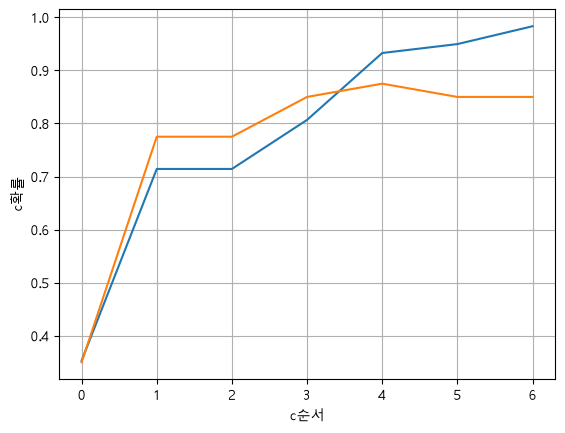

In [34]:
list1 = list(range(7))
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('c순서')
plt.ylabel('c확률')
plt.grid()
plt.show()

In [41]:
print('train정확도:',lr.score(train_scaled,train_label))
print('test정확도:',lr.score(test_scaled,test_label))

train정확도: 0.9831932773109243
test정확도: 0.85


In [42]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [40]:
# 실제입력받아 예측하시오.
# predict = lr.predict(test_scaled[:1])
# print('분류생선:',predict)
# proba = lr.predict_proba(test_scaled[:1])
# print('확률:',proba)

predict = lr.predict(test_scaled[:1])
print('분류생선:',predict)
proba = lr.predict_proba(test_scaled[:1])
# if 문을 넣어서 확인 
if predict[0] == "Bream":
    result = proba[0][0]
elif predict[0] == "Parkki":
    result = proba[0][1]
elif predict[0] == "Perch":
    result = proba[0][2]
elif predict[0] == "Pike":
    result = proba[0][3]
elif predict[0] == "Roach":
    result = proba[0][4]
elif predict[0] == "Smelt":
    result = proba[0][5]
elif predict[0] == "Whitefish":
    result = proba[0][6]
print('확률:',proba[0][2])

분류생선: ['Roach']
확률: 0.11600337801307004
